## Table of Contents

#### Part I: Research Question

A1. [Research Question](#A1.-Research-Question)

A2. [Defined Goal](#A2.-Defined-Goal)

#### Part II: Technique Justification

B1. [Explanation of PCA](#B1.-Explanation-of-PCA)

B2. [Summary of PCA Assumptions](#B2.-Summary-of-PCA-Assumptions)

#### Part III: Data Preparation

C1. [Continuous Dataset Variables](#C1.-Continuous-Dataset-Variables)

C2. [Standardization of Dataset Variables](#C2.-Standardization-of-Dataset-Variables)


#### Part IV: Analysis

D1. [Principal Components](#D1.-Principal-Components)

D2. [Identification of Total Number of Components](#D2.-Identification-of-Total-Number-of-Components)

D3. [Variance of Components](#D3.-Variance-of-Components)

D4. [Total Variance Captured by Components](#D4.-Total-Variance-Captured-by-Components)

D5. [Summary of Data Analysis](#D5.-Summary-of-Data-Analysis)

#### Part V: Attachments

E. [Sources of Third-Party Code](#G.-Sources-of-Third-Party-Code)

F. [Sources](#H.-Sources)

### Part I: Research Question

#### A1. Research Question

This analysis will seek to determine whether principal component analysis can be used to reduce dimensionality in the churn dataset by creating principal components, or PC's, which are representative of specified continuous variables in the originating dataset.

#### A2. Defined Goal

The goal of this analysis will be to identify more than one principal component that can be used to represent the five continuous variables from the churn dataset: Income, Outage_sec_perweek, Tenure, MonthlyCharge, and Bandwidth_GB_Year.

### Part II: Technique Justification

#### B1. Explanation of PCA

Principal component analysis, or PCA, is a type of dimensionality reduction technique that allows an analyst to reduce the total number of features contained within a dataset, while still maintaining the information that is most important to the analysis being performed. Dimensionality reduction methods like PCA are useful when a dataset has too many features that could lead to issues such as slow processing times, or overfitting of data in the model. (Bigabid, n.d.; Soriano, n.d.).

PCA works by transforming data into new features, referred to as principal components, which are used to represent the most important data from the original datset. These principal components do not have any overlap with one another and therefore can each be considered as representative of unique important features within the original dataset. This can assist with addressing numerous potential issues such as multicollinearity and noise reduction. (GeeksForGeeks, 2025)

For this analysis, PCA will be used to reduce the dimensionality of the data by producing principal components that can be used to represent the continuous variables contained within the input dataset. The expected outcome is to produce PCs that satisfactorily represent the aforementioned variables while also addressing issues such as overfitting and processing overhead involved with future analysis.

#### B2. Summary of PCA Assumptions

PCA assumes linear relationships exist between variables; by its nature, PCA re-expresses data as a linear combination of the data used in the analysis. (Shlens, 2005)

### Part III: Data Preparation

#### C1. Continuous Dataset Variables

The continuous dataset variables that will be used as part of this analysis are as follows:

1. **Income**: The customer’s annual household income.
2. **Outage_sec_perweek**: The average service outage length per week in the customer's neighborhood, measured in seconds.
3. **Tenure**: The number of months that the customer has been actively subscribed with the service provider.
4. **MonthlyCharge**: The average amount of money charged to the customer on a monthly basis.
5. **Bandwidth_GB_Year**: The average amount of data used by the customer over the past year, measured in GB.

#### C2. Standardization of Dataset Variables

The below code standardizes the continues variables that were identified in the previous section. It does this in several steps:

1. Importing the necessary packages for use in the analysis
2. Extracting just the five continuous variables: Income, Outage_sec_perweek, Tenure, MonthlyCharge, and Bandwidth_GB_Year
3. Printing summaries of the dataframe containing the extracted variables
4. Using StandardScaler from scikit-learn to scale the data
5. Outputting the scaled data to an external .csv file for reference: churn_scaled_df.csv

In [1]:
# Import necessary packages for use in this analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Import dataset
churnfile = pd.read_csv('../data/churn_clean.csv',index_col=0, keep_default_na=False, na_values=['NA'])  # 'None' is a valid InternetService value

# Extract just the continuous variables for use in PCA
# Note that discrete numeric variables are not included here
churn_cont = churnfile[['Income','Outage_sec_perweek','Tenure','MonthlyCharge','Bandwidth_GB_Year']]

churn_cont.info()
churn_cont.head()

<class 'pandas.core.frame.DataFrame'>
Index: 10000 entries, 1 to 10000
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Income              10000 non-null  float64
 1   Outage_sec_perweek  10000 non-null  float64
 2   Tenure              10000 non-null  float64
 3   MonthlyCharge       10000 non-null  float64
 4   Bandwidth_GB_Year   10000 non-null  float64
dtypes: float64(5)
memory usage: 468.8 KB


,Income,Outage_sec_perweek,Tenure,MonthlyCharge,Bandwidth_GB_Year
CaseOrder,,,,,
1,28561.99,7.978323,6.795513,172.455519,904.536110
2,21704.77,11.699080,1.156681,242.632554,800.982766
3,9609.57,10.752800,15.754144,159.947583,2054.706961
4,18925.23,14.913540,17.087227,119.956840,2164.579412
5,40074.19,8.147417,1.670972,149.948316,271.493436


In [2]:
# Use StandardScaler to scale the data

scaler = StandardScaler()
scaler.fit(churn_cont)
StandardScaler(copy=True, with_mean=True, with_std=True)

churn_scaled = scaler.transform(churn_cont)
churn_scaled_df = pd.DataFrame(churn_scaled)
churn_scaled_df = churn_scaled_df.set_axis(['Income','Outage_sec_perweek','Tenure',
                                            'MonthlyCharge','Bandwidth_GB_Year'], axis=1, copy=False)

print(churn_scaled_df)

        Income  Outage_sec_perweek    Tenure  MonthlyCharge  Bandwidth_GB_Year
0    -0.398778           -0.679978 -1.048746      -0.003943          -1.138487
1    -0.641954            0.570331 -1.262001       1.630326          -1.185876
2    -1.070885            0.252347 -0.709940      -0.295225          -0.612138
3    -0.740525            1.650506 -0.659524      -1.226521          -0.561857
4     0.009478           -0.623156 -1.242551      -0.528086          -1.428184
...        ...                 ...       ...            ...                ...
9995  0.564456           -0.196888  1.273401      -0.294484           1.427298
9996 -0.201344           -1.095915  1.002740       0.811726           1.054194
9997  0.219037           -1.146198  0.487513      -0.061729           0.350984
9998 -0.820588            0.695616  1.383018       1.863005           1.407713
9999 -1.091760            0.589028  1.090120       1.044672           1.128163

[10000 rows x 5 columns]


A copy of the scaled dataset that will be used to create the principal components in this analysis has been attached as a csv file, "churn_scaled_df.csv".

In [3]:
churn_scaled_df.to_csv('churn_scaled_df.csv', index=False)

### Part IV: Analysis

#### D1. Principal Components

The below code creates five principal components, using the PCA functionality from scikit-learn. It then prints out a load matrix showing the five PC's.

In [4]:
# Define PCA object
pca = PCA(n_components=5, random_state=1337)

# Fit data to model
PC = pca.fit_transform(churn_scaled_df)

# Generate load matrix
load_matrix = pd.DataFrame(pca.components_, columns = churn_scaled_df.columns, index=('PC1','PC2','PC3','PC4','PC5'))

# Print load matrix
load_matrix

,Income,Outage_sec_perweek,Tenure,MonthlyCharge,Bandwidth_GB_Year
PC1,0.003936,0.005858,0.705844,0.040748,0.707159
PC2,-0.365683,0.682929,-0.039973,0.631099,-0.000089
PC3,0.897256,0.078077,-0.030063,0.433512,-0.000613
PC4,0.247368,0.726276,0.035159,-0.640363,-0.005588
PC5,-0.001250,0.000034,-0.705724,-0.045361,0.707032


#### D2. Identification of Total Number of Components

One appropriate metric that can be used for determing the total number of principal components is the "Kaiser rule", which posits that PCs with eigenvalues that are greater than 1 should be kept, while PCs with eigenvalues equal to or less than 1 can be discarded. 

The code block below first calculates the eigenvalues for each of the five PCs that were created earlier; then, it generates a Scree plot using matplotlib to show the eigenvalues for each PC. Based on this plot, the Kaiser rule can be applied to identify which principal components to keep.

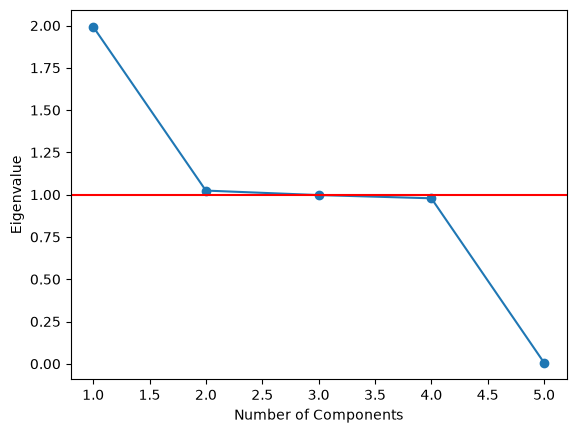

In [5]:
# Calculate covariance and vectors, then define eigenvalues
covar_mtx = np.dot(churn_scaled_df.T, churn_scaled_df) / churn_scaled.shape[0]
eigenvals = [np.dot(eigenvector.T, np.dot(covar_mtx, eigenvector)) for eigenvector in pca.components_]

# Create scree plot
plt.plot(np.arange(1,len(eigenvals)+1),eigenvals,marker='o')
plt.xlabel('Number of Components')
plt.ylabel('Eigenvalue')
plt.axhline(y=1, color="red")
plt.show()

As we can see above, PC's 1 and 2 have eigenvalues above 1; following the Kaiser rule, these two PC's can be kept, while all other PC's will be discarded. The PCA model can be re-created and a new loading matrix can be printed based on just these two principal components:

In [6]:
# Define new PCA object with n_components = 2
pca_final = PCA(n_components=2, random_state=1337)

# Fit data to final model
PC = pca_final.fit_transform(churn_scaled_df)

# Generate final load matrix
load_matrix_final = pd.DataFrame(pca_final.components_, columns = churn_scaled_df.columns, index=('PC1','PC2'))

# Print final load matrix
load_matrix_final

,Income,Outage_sec_perweek,Tenure,MonthlyCharge,Bandwidth_GB_Year
PC1,0.003936,0.005858,0.705844,0.040748,0.707159
PC2,-0.365683,0.682929,-0.039973,0.631099,-0.000089


#### D3. Variance of Components

After applying the Kaiser rule above, it was determined that PC1 and PC2 could both be kept, while PC3, PC4, and PC5 should be discarded. The variance of PC1 and PC2 can be calculated as follows:

In [7]:
# Print the explained variance of the first two PCs from the model created above
print(pca_final.explained_variance_[:2])

[1.99338587 1.02423108]


The explained variances of PC1 and PC2 are 1.99338587 and 1.02423108, respectively.

#### D4. Total Variance Captured by Components

In [8]:
print(np.sum(pca_final.explained_variance_ratio_[:2]))

0.6034630363799048


The total variance captured by PC1 and PC2 is around 0.6035, indicating that these two principal components explain roughly 60.35% of the total variance in the dataset. 

#### D5. Summary of Data Analysis

The data analysis performed in this paper successfully reduced dimensionality within the churn dataset by transforming five of the continuous variables within the dataset into two principal components, identified as PC1 and PC2, which together account for 60.35% of the total variance within the dataset.

The initial step of this analysis involved creating five principal components, using the five continuous variables from the initial churn dataset. These variables were Income, Outagesec_per_week, Tenure, MonthlyCharge, and Bandwidth_GB_Year; they were placed into their own dataset and then standardized using StandardScaler from scikit-learn. A loading matrix was then created in order to show the effect contributed by each of these five variables against the five initial principal components. I then created a Scree plot, showing the eigenvalues of each of these five initial PC's. The Kaiser rule was then applied, so that all PC's with eigenvalues of greater than 1 were kept, and PC's with eigenvalues equal to or less than 1 were discarded. Based on this application of the Kaiser rule, PC1 and PC2 were kept, and PC3, PC4, and PC5 were all discarded.

The result of this analysis was the creation of two principal components, PC1 and PC2, that could effectively represent the five aforementioned continuous variables that were used in their creation.

### Part V: Attachments

#### E. Sources of Third-Party Code

Scikit-Learn Documentation. *PCA*. 2025. https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html

Scikit-Learn Documentation. *StandardScaler*. 2025. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

#### F. Sources

Bigabid. *PCA: What, How, and Why*. Retrieved August 2, 2025 from https://www.bigabid.com/what-is-pca-and-how-can-i-use-it/


GeeksForGeeks. *Introduction to Dimensionality Reduction*. May 26, 2025. https://www.geeksforgeeks.org/machine-learning/dimensionality-reduction/

GeeksForGeeks. *Principal Component Analysis(PCA)*. July 11, 2025. https://www.geeksforgeeks.org/data-analysis/principal-component-analysis-pca/

Matplotlib Documentation. *Quick Start Guide.* 2024. https://matplotlib.org/stable/users/explain/quick_start.html

NumPy Documentation. *What is NumPy?* 2024. https://numpy.org/doc/2.1/user/whatisnumpy.html#whatisnumpy

Pandas Documentation. *Intro to Pandas.* 2024. https://pandas.pydata.org/docs/getting_started/index.html#intro-to-pandas

Scikit-Learn Documentation. *Getting Started.* 2024. https://scikit-learn.org/stable/getting_started.html

Shlens. *A Tutorial on Principal Component Analysis.* 2005. https://www.cs.cmu.edu/~elaw/papers/pca.pdf

Soriano, P.V. *Advantages & Disadvantages of Principal Component Analysis (PCA)*. Statistics Globe. Retrieved August 2, 2025 from https://statisticsglobe.com/advantages-disadvantages-pca